# Tutorial: Red Neuronal Multicapa (MLP) con el Dataset Iris

**Objetivo:** implementar, entrenar y evaluar una red neuronal multicapa usando Python y `scikit-learn`.

En este tutorial se siguen las etapas principales de un pipeline de Machine Learning: selección y exploración de datos, preprocesamiento, selección y entrenamiento del modelo, y evaluación.

> **Nota:** Iris puede cargarse directamente desde `scikit-learn`. Si tu profesor compartió un archivo Iris específico en Google Classroom, puedes sustituir la celda de carga por la lectura de ese archivo, conservando el resto del pipeline.


## 1. Fundamentos teóricos del MLP

Un **Perceptrón Multicapa (MLP)** es una red neuronal artificial formada por capas de neuronas conectadas:

- **Capa de entrada:** recibe las características de cada flor.
- **Capas ocultas:** combinan las entradas mediante pesos, bias y funciones de activación para aprender patrones.
- **Capa de salida:** produce la predicción. En este ejercicio identifica una de las tres especies de Iris.

Cada conexión tiene un **peso** que determina la influencia de una entrada. El **bias** permite desplazar la suma ponderada. Una función de activación introduce no linealidad, lo que permite aprender relaciones más complejas que una clasificación lineal simple.

Durante el entrenamiento, el MLP compara sus predicciones con las etiquetas correctas y ajusta los parámetros mediante retropropagación del error (*backpropagation*) y un optimizador. En `scikit-learn`, `MLPClassifier` implementa este proceso.

El dataset Iris contiene tres clases: *setosa*, *versicolor* y *virginica*. Cada muestra se describe con cuatro medidas de la flor.


## 2. Modelo matemático del MLP

Para una neurona, la suma ponderada se expresa como:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

donde:

- $x_i$: valor de la característica de entrada.
- $w_i$: peso asociado a esa característica.
- $b$: bias o sesgo de la neurona.
- $z$: suma ponderada antes de aplicar la función de activación.

La salida de la neurona se obtiene aplicando una función de activación:

$$
a = f(z)
$$

En una capa oculta, el cálculo se puede representar como:

$$
\mathbf{a}^{(l)} = f\left(\mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right)
$$

La capa de salida genera valores utilizados para clasificar la muestra. El entrenamiento ajusta los pesos y bias para reducir una función de pérdida que mide la diferencia entre las predicciones y las etiquetas reales.

En este ejemplo se configurará una capa oculta con 10 neuronas y la función de activación ReLU. El clasificador utilizará su configuración de salida multiclase predeterminada para distinguir las tres especies.


## 3. Pipeline: selección y exploración del dataset

### 3.1 Cargar las bibliotecas y los datos

Primero importamos las herramientas que se utilizarán. `load_iris` carga el dataset de ejemplo; `pandas` organiza los datos en una tabla y `matplotlib` genera la gráfica.


In [1]:
# Importar pandas para organizar los datos en una tabla.
import pandas as pd

# Importar matplotlib para crear gráficas.
import matplotlib.pyplot as plt

# Importar el dataset Iris incluido en scikit-learn.
from sklearn.datasets import load_iris

# Cargar los datos y sus descripciones.
iris = load_iris()

# Crear una tabla con las cuatro características de cada flor.
X = pd.DataFrame(iris.data, columns=iris.feature_names)

# Guardar la especie de cada flor como variable objetivo.
y = pd.Series(iris.target, name="especie")

# Mostrar las primeras filas para observar la estructura.
display(X.head())

# Mostrar las primeras etiquetas numéricas.
display(y.head())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


0    0
1    0
2    0
3    0
4    0
Name: especie, dtype: int64

### 3.2 Descripción del dataset

Iris contiene 150 muestras, cuatro características numéricas y tres clases. Las características son longitud y anchura del sépalo, y longitud y anchura del pétalo, medidas en centímetros.

La variable objetivo `y` usa etiquetas numéricas: 0, 1 y 2. Estas corresponden a las especies almacenadas en `iris.target_names`.


In [2]:
# Mostrar el número de muestras y de características.
print("Cantidad de muestras:", X.shape[0])
print("Cantidad de características:", X.shape[1])

# Mostrar los nombres de las características.
print("\nCaracterísticas:")
for nombre in X.columns:
    print("-", nombre)

# Mostrar las clases disponibles y su correspondencia con las etiquetas.
print("\nClases:")
for indice, nombre in enumerate(iris.target_names):
    print(f"{indice}: {nombre}")

# Mostrar estadísticas descriptivas de las características.
display(X.describe())

# Contar cuántas muestras hay de cada clase.
print("\nCantidad de muestras por clase:")
print(y.map(dict(enumerate(iris.target_names))).value_counts())


Cantidad de muestras: 150
Cantidad de características: 4

Características:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)

Clases:
0: setosa
1: versicolor
2: virginica


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Cantidad de muestras por clase:
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### 3.3 Scatter plot

Un *scatter plot* o diagrama de dispersión permite visualizar la relación entre dos características. Aquí se muestran la longitud y anchura del pétalo; cada color representa una especie.

La gráfica sirve para explorar si las clases parecen separarse visualmente. Esta visualización es exploratoria y no sustituye la evaluación cuantitativa del modelo.


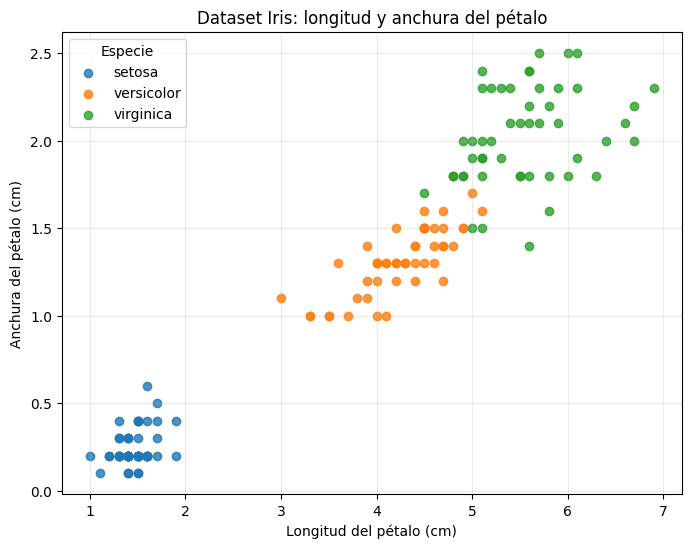

In [3]:
# Crear una figura para el diagrama de dispersión.
plt.figure(figsize=(8, 6))

# Dibujar un punto por muestra y colorearlo según su especie.
for clase, nombre in enumerate(iris.target_names):
    # Seleccionar únicamente las filas de la clase actual.
    mascara = y == clase

    # Usar longitud del pétalo en el eje X y anchura en el eje Y.
    plt.scatter(
        X.loc[mascara, "petal length (cm)"],
        X.loc[mascara, "petal width (cm)"],
        label=nombre,
        alpha=0.8
    )

# Añadir títulos, etiquetas y leyenda.
plt.title("Dataset Iris: longitud y anchura del pétalo")
plt.xlabel("Longitud del pétalo (cm)")
plt.ylabel("Anchura del pétalo (cm)")
plt.legend(title="Especie")
plt.grid(True, alpha=0.25)

# Mostrar la gráfica.
plt.show()


## 4. Pipeline: preprocesamiento

### 4.1 Splitting: separar entrenamiento y prueba

Se separan los datos en un conjunto de entrenamiento (80 %) y otro de prueba (20 %). El modelo aprende con el primero y se evalúa con el segundo, que no se utiliza para entrenarlo.

`stratify=y` conserva aproximadamente la proporción de cada especie en ambos conjuntos. `random_state` permite reproducir la misma separación al ejecutar de nuevo el notebook.


In [4]:
# Importar la función para dividir los datos.
from sklearn.model_selection import train_test_split

# Dividir las características y etiquetas en entrenamiento y prueba.
X_train, X_test, y_train, y_test = train_test_split(
    X,                 # Características de entrada.
    y,                 # Etiquetas o variable objetivo.
    test_size=0.20,    # Reservar el 20 % para la prueba.
    random_state=42,   # Fijar la semilla para reproducibilidad.
    stratify=y         # Mantener la proporción de las clases.
)

# Mostrar los tamaños de los conjuntos resultantes.
print("Muestras para entrenamiento:", X_train.shape[0])
print("Muestras para prueba:", X_test.shape[0])


Muestras para entrenamiento: 120
Muestras para prueba: 30


### 4.2 Scaling: escalar las características

Las características pueden tener rangos distintos. `StandardScaler` transforma cada característica para que, usando los datos de entrenamiento, tenga media cercana a 0 y desviación estándar cercana a 1.

**Importante para evitar fuga de datos:** el escalador se ajusta solo con `X_train`. Después se utiliza para transformar tanto el conjunto de entrenamiento como el de prueba. No se debe ajustar con todo el dataset antes de dividirlo.


In [5]:
# Importar el escalador estándar.
from sklearn.preprocessing import StandardScaler

# Crear el objeto encargado de escalar las características.
scaler = StandardScaler()

# Calcular media y desviación estándar usando solo entrenamiento.
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar los mismos parámetros al conjunto de prueba.
X_test_scaled = scaler.transform(X_test)

# Mostrar algunas filas escaladas para verificar el resultado.
print("Primeras cinco muestras de entrenamiento escaladas:")
print(X_train_scaled[:5])


Primeras cinco muestras de entrenamiento escaladas:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


## 5. Pipeline: selección del modelo y entrenamiento

Se utilizará `MLPClassifier`, una implementación de perceptrón multicapa para tareas de clasificación.

Configuración seleccionada:

- `hidden_layer_sizes=(10,)`: una capa oculta con 10 neuronas.
- `activation="relu"`: función de activación ReLU para la capa oculta.
- `solver="adam"`: optimizador para ajustar los parámetros.
- `max_iter=1000`: límite máximo de iteraciones de entrenamiento.
- `random_state=42`: ayuda a reproducir la inicialización aleatoria.

Se usa `early_stopping=True` para permitir que el entrenamiento se detenga si la puntuación de validación deja de mejorar. El MLP no necesita que se programen manualmente las actualizaciones de cada peso: la biblioteca realiza esos cálculos internamente.


In [6]:
# Importar el clasificador de red neuronal multicapa.
from sklearn.neural_network import MLPClassifier

# Crear el modelo MLP con los parámetros elegidos.
modelo = MLPClassifier(
    hidden_layer_sizes=(10,),  # Una capa oculta de 10 neuronas.
    activation="relu",         # Activación ReLU en la capa oculta.
    solver="adam",             # Optimizador para el aprendizaje.
    max_iter=1000,             # Máximo de iteraciones de entrenamiento.
    random_state=42,           # Hacer reproducible la inicialización.
    early_stopping=True        # Detener si la validación deja de mejorar.
)

# Entrenar el modelo usando solo los datos de entrenamiento escalados.
modelo.fit(X_train_scaled, y_train)

# Confirmar cuántas iteraciones se utilizaron.
print("Iteraciones realizadas:", modelo.n_iter_)

# Mostrar la pérdida final del entrenamiento.
print("Pérdida final:", modelo.loss_)


Iteraciones realizadas: 42
Pérdida final: 1.1492995439653713


## 6. Pipeline: evaluación del modelo

### 6.1 Accuracy

El *accuracy* es la proporción de predicciones correctas sobre el total de muestras evaluadas:

$$
\text{Accuracy} = \frac{\text{Predicciones correctas}}{\text{Total de predicciones}}
$$

Se calculará sobre el conjunto de prueba, que se mantuvo separado del entrenamiento. El resultado estará entre 0 y 1; cuanto más alto, mayor proporción de clasificaciones correctas.


In [7]:
# Importar la métrica accuracy.
from sklearn.metrics import accuracy_score

# Predecir las especies para las muestras de prueba escaladas.
y_pred = modelo.predict(X_test_scaled)

# Calcular la proporción de predicciones correctas.
accuracy = accuracy_score(y_test, y_pred)

# Mostrar el resultado como decimal y porcentaje.
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy porcentual: {accuracy * 100:.2f}%")


Accuracy: 0.1667
Accuracy porcentual: 16.67%


### 6.2 Matriz de confusión

La matriz de confusión compara las etiquetas reales con las predicciones:

- Las filas representan las clases reales.
- Las columnas representan las clases predichas.
- Los valores de la diagonal principal indican clasificaciones correctas.
- Los valores fuera de la diagonal indican errores de clasificación.

La matriz permite observar qué especies se confunden entre sí, información que no se obtiene con el accuracy por sí solo.


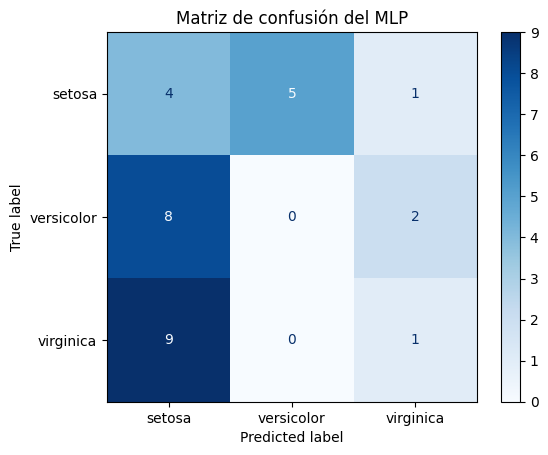

Matriz de confusión:
[[4 5 1]
 [8 0 2]
 [9 0 1]]


In [8]:
# Importar las funciones para calcular y visualizar la matriz de confusión.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcular la matriz usando las etiquetas reales y las predicciones.
matriz = confusion_matrix(y_test, y_pred)

# Mostrar la matriz con nombres de especies en los ejes.
visualizador = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=iris.target_names
)

# Crear la gráfica de la matriz de confusión.
visualizador.plot(cmap="Blues", values_format="d")

# Añadir un título y mostrar la figura.
plt.title("Matriz de confusión del MLP")
plt.show()

# Imprimir también la matriz en formato numérico.
print("Matriz de confusión:")
print(matriz)


## 7. Conclusiones

En este tutorial se recorrió el pipeline de Machine Learning para clasificar las especies del dataset Iris con una red neuronal multicapa:

1. Se cargó y describió el dataset, y se visualizó la relación entre dos características.
2. Se dividieron los datos en entrenamiento y prueba.
3. Se escalaron las características sin utilizar información del conjunto de prueba para ajustar el escalador.
4. Se configuró y entrenó un `MLPClassifier`.
5. Se evaluó el desempeño con accuracy y matriz de confusión.


